# Object and arena marking (Stage G2)

Click the object(s) and the arena corners on the median frame of each object / open-field session. Positions are recorded nowhere else, so this is the source of `objects` in the data_dic.

**How to use**
1. Run the setup cell, pick `DATASET` (`mec` or `lec`) and your initials.
2. Run the *arena corners* cell. mEC: once per arena (the big field does not move). LEC: **once per object / open-field session**, because the small box shifts between sessions (user, 2026-09-18). Click the **four inner corners of the arena floor** in the order **top-left, top-right, bottom-right, bottom-left** as seen in the image, press **Enter** (or *Save corners*); the next session appears. Sessions already in the CSV are skipped, so you can stop and resume.
3. Run the *objects* cell. For each session: click the **centre of an object**, then type its label in the box (e.g. `bottle`, `cube`; reuse labels for the same physical object across sessions), press **Add**; optionally click once on the object's edge to record a radius before pressing Add. Repeat for every object in the frame. **Next** moves on (an open-field session with no object is fine: just press Next). **Undo** removes the last click. Everything is appended to the CSV immediately, so you can stop and resume.

Needs the `ipympl` widget backend (present in the `maze_ephys` and `histology` envs). If clicks do nothing, the kernel is not running one of those envs.

Outputs: `data/processed_data/object_positions_{dataset}.csv` and `arena_corners_{dataset}.csv` in the dataset tree; pixel coordinates are converted to cm with `arena_calibration` after the corners are in (`object_checks.py`).

In [1]:
%matplotlib widget
import os, sys, csv, datetime
from pathlib import Path
DATASET = 'lec'          # 'mec' or 'lec'
CLICKED_BY = 'AH'
os.environ['TSA_DATASET'] = DATASET
REPO = Path('/ceph/behrens/adam_harris/Taskspace_abstraction_lEC')
sys.path.insert(0, str(REPO / 'code')); sys.path.insert(0, str(REPO / 'code' / 'preprocessing'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.image as mpimg
import ipywidgets as W
from IPython.display import display
import recday_registry as rr
# the tree from the dataset NAME, not rr.REPO_ROOT: a kernel that already imported the registry
# for the other dataset keeps that root until restarted
ROOT = rr.DATASETS[DATASET]['root']
FRAMES = ROOT / 'data' / 'processed_data' / 'object_frames'
OBJ_CSV = ROOT / 'data' / 'processed_data' / f'object_positions_{DATASET}.csv'
ARENA_CSV = ROOT / 'data' / 'processed_data' / f'arena_corners_{DATASET}.csv'
index = pd.read_csv(sorted(FRAMES.glob(f'index_{DATASET}*.csv'))[-1])
index = index[index.status.isin(['written', 'exists_skipped'])].reset_index(drop=True)
def arena_of(mouse):
    return 'bigfield' if DATASET == 'mec' else ('openfield_box2' if mouse in ('ah08', 'ly06') else 'openfield_box1')
index['arena'] = index.mouse.map(arena_of)
def append_row(path, row, header):
    new = not path.exists()
    with open(path, 'a', newline='') as f:
        w = csv.DictWriter(f, fieldnames=header)
        if new: w.writeheader()
        w.writerow(row)
def done_sessions(path):
    if not path.exists(): return set()
    d = pd.read_csv(path); return set(zip(d.recday, d.session))
print(f'{len(index)} frames for {DATASET}: ' + ', '.join(f"{k} {v}" for k, v in index.kind.value_counts().items()))
print('already marked (objects):', len(done_sessions(OBJ_CSV)), '| corner sets done:', (len(pd.read_csv(ARENA_CSV)) // 4) if ARENA_CSV.exists() else 0)

20 frames for lec: object 20
already marked (objects): 20 | corner sets done: 0


In [2]:
index.arena.unique()

<ArrowStringArray>
['openfield_box2', 'openfield_box1']
Length: 2, dtype: str

## Arena corners
mEC: once per arena. LEC: every object / open-field session (the box shifts between sessions). Click TL, TR, BR, BL of the inner floor, then Enter or **Save corners**. **u** / Undo removes the last click, **Skip** leaves the session for later.


20 sessions need corners


Output()

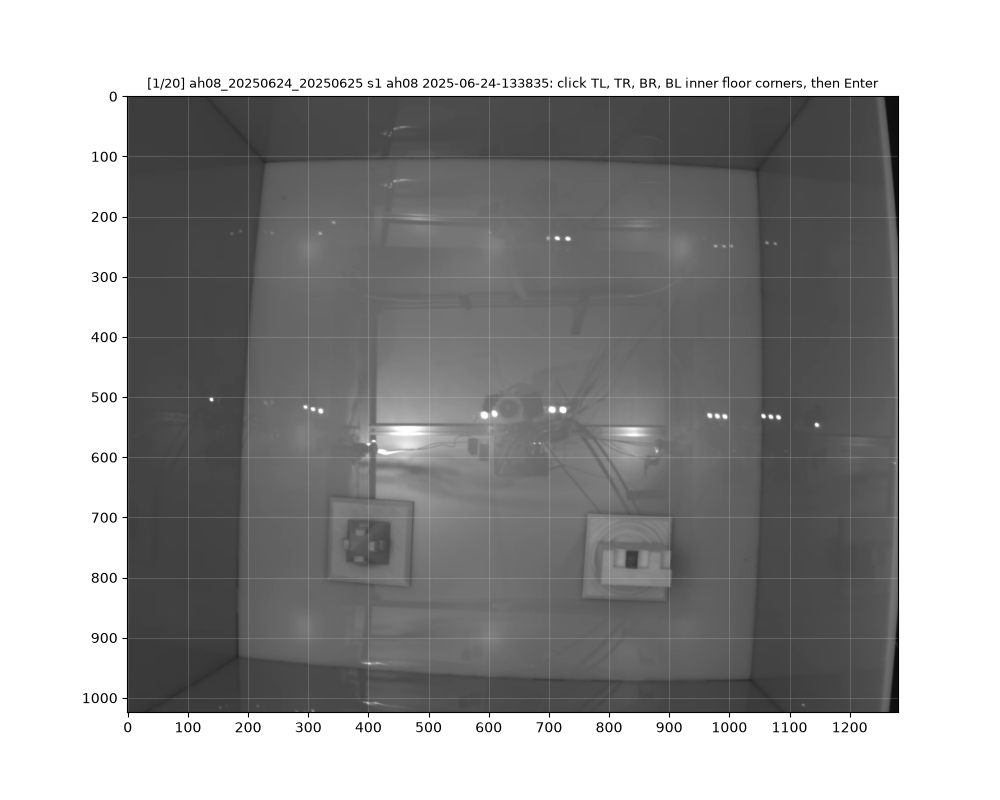

In [3]:
ARENA_HEADER = ['arena', 'recday', 'session', 'mouse', 'stamp', 'kind', 'corner', 'x_px', 'y_px', 'frame', 'clicked_by', 'timestamp']
PER_SESSION = DATASET == 'lec'      # the small box shifts between sessions (user, 2026-09-18); the big field does not
def corners_done():
    if not ARENA_CSV.exists(): return set()
    d = pd.read_csv(ARENA_CSV)
    if PER_SESSION:
        return set(zip(d.recday, d.session)) if 'recday' in d.columns else set()
    return set(d.arena)
if PER_SESSION:
    ctodo = index[index.kind.isin(['object', 'openfield'])].copy()
    ctodo = ctodo[[(r, s) not in corners_done() for r, s in zip(ctodo.recday, ctodo.session)]].reset_index(drop=True)
else:
    ctodo = index[~index.arena.isin(corners_done())].sort_values('kind', key=lambda k: k != 'openfield').drop_duplicates('arena').reset_index(drop=True)
print(f'{len(ctodo)} {"sessions" if PER_SESSION else "arenas"} need corners')
cstate = dict(i=0, clicks=[], marks=[])
cfig, cax = plt.subplots(figsize=(10, 8))
cb_save, cb_undo, cb_skip, cout = W.Button(description='Save corners'), W.Button(description='Undo'), W.Button(description='Skip'), W.Output()
def cshow():
    cax.clear(); cstate['clicks'].clear(); cstate['marks'].clear()
    if cstate['i'] >= len(ctodo): cax.set_title('all corners done'); cfig.canvas.draw_idle(); return
    r = ctodo.iloc[cstate['i']]
    p = FRAMES / f"{r.mouse}_{r.stamp}_{r.kind}_median.png"
    cax.imshow(mpimg.imread(p)); cax.set_xticks(range(0, 1281, 100)); cax.set_yticks(range(0, 1025, 100)); cax.grid(color='w', alpha=0.15)
    who = f"{r.recday} s{r.session} {r.mouse} {r.stamp}" if PER_SESSION else r.arena
    cax.set_title(f"[{cstate['i']+1}/{len(ctodo)}] {who}: click TL, TR, BR, BL inner floor corners, then Enter", fontsize=9)
    cfig.canvas.draw_idle()
def con_click(ev):
    if ev.inaxes != cax or ev.button != 1 or cstate['i'] >= len(ctodo) or len(cstate['clicks']) >= 4: return
    cstate['clicks'].append((ev.xdata, ev.ydata))
    cstate['marks'].append(cax.plot(ev.xdata, ev.ydata, 'r+', ms=14, mew=2)[0]); cstate['marks'].append(cax.text(ev.xdata + 8, ev.ydata - 8, ['TL', 'TR', 'BR', 'BL'][len(cstate['clicks']) - 1], color='r', fontsize=9))
    cfig.canvas.draw_idle()
def cundo(_=None):
    if cstate['clicks']: cstate['clicks'].pop(); cstate['marks'].pop().remove(); cstate['marks'].pop().remove(); cfig.canvas.draw_idle()
def csave(_=None):
    with cout:
        if len(cstate['clicks']) != 4: print(f'need 4 corners, have {len(cstate["clicks"])}'); return
        r = ctodo.iloc[cstate['i']]
        for k, (x, y) in enumerate(cstate['clicks']):
            append_row(ARENA_CSV, dict(arena=r.arena, recday=r.recday if PER_SESSION else '', session=int(r.session) if PER_SESSION else '', mouse=r.mouse, stamp=r.stamp, kind=r.kind, corner=k, x_px=round(x, 1), y_px=round(y, 1), frame=f"{r.mouse}_{r.stamp}_{r.kind}_median.png", clicked_by=CLICKED_BY, timestamp=datetime.datetime.now().isoformat(timespec='seconds')), ARENA_HEADER)
        print(f'saved 4 corners for {r.recday + " s" + str(r.session) if PER_SESSION else r.arena}')
    cstate['i'] += 1; cshow()
def cskip(_=None):
    cstate['i'] += 1; cshow()
cfig.canvas.mpl_connect('button_press_event', con_click)
cfig.canvas.mpl_connect('key_press_event', lambda ev: csave() if ev.key == 'enter' else (cundo() if ev.key == 'u' else None))
cb_save.on_click(csave); cb_undo.on_click(cundo); cb_skip.on_click(cskip)
display(W.HBox([cb_save, cb_undo, cb_skip]), cout); cshow()


## Objects (one session at a time)
Click object centre → type label → (optional edge click) → **Add**. **Next** when the frame is done. Sessions already in the CSV are skipped.

20 object sessions to mark


Output()

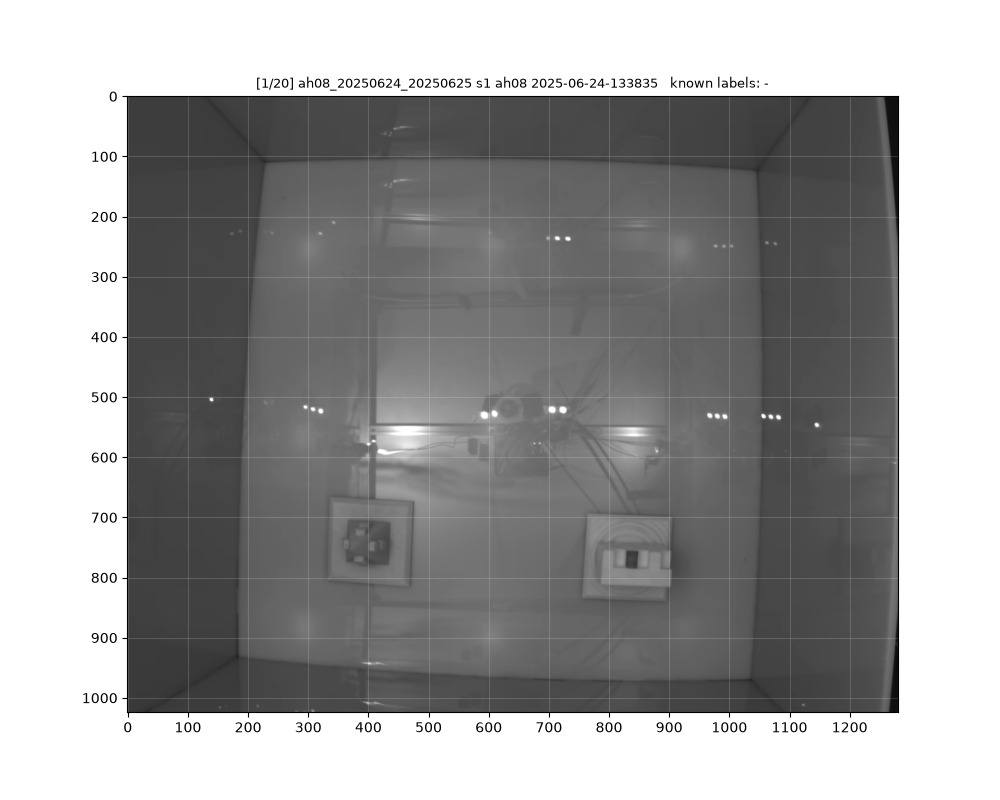

In [7]:
OBJ_HEADER = ['recday', 'session', 'mouse', 'stamp', 'kind', 'object_label', 'x_px', 'y_px', 'radius_px', 'frame', 'clicked_by', 'timestamp']
todo = index[index.kind == 'object'].copy()
todo = todo[[ (r, s) not in done_sessions(OBJ_CSV) for r, s in zip(todo.recday, todo.session)]].reset_index(drop=True)
print(f'{len(todo)} object sessions to mark')
state = dict(i=0, clicks=[], marks=[])
fig, ax = plt.subplots(figsize=(10, 8))
label_box = W.Text(description='label', placeholder='e.g. bottle'); b_add = W.Button(description='Add object'); b_next = W.Button(description='Next session'); b_undo = W.Button(description='Undo click'); out = W.Output()
known = sorted(set(pd.read_csv(OBJ_CSV).object_label.astype(str))) if OBJ_CSV.exists() else []
def show():
    ax.clear(); state['clicks'].clear(); state['marks'].clear()
    if state['i'] >= len(todo): ax.set_title('all sessions marked'); fig.canvas.draw_idle(); return
    r = todo.iloc[state['i']]
    p = FRAMES / f"{r.mouse}_{r.stamp}_{r.kind}_median.png"
    ax.imshow(mpimg.imread(p)); ax.set_xticks(range(0, 1281, 100)); ax.set_yticks(range(0, 1025, 100)); ax.grid(color='w', alpha=0.15)
    ax.set_title(f"[{state['i']+1}/{len(todo)}] {r.recday} s{r.session} {r.mouse} {r.stamp}   known labels: {', '.join(known) or '-'}", fontsize=9)
    fig.canvas.draw_idle()
def on_click(ev):
    if ev.inaxes != ax or ev.button != 1 or state['i'] >= len(todo): return
    state['clicks'].append((ev.xdata, ev.ydata)); state['marks'].append(ax.plot(ev.xdata, ev.ydata, 'r+' if len(state['clicks']) == 1 else 'y+', ms=14, mew=2)[0]); fig.canvas.draw_idle()
def add(_=None):
    with out:
        if not state['clicks']: print('click the object centre first'); return
        lab = label_box.value.strip()
        if not lab: print('type a label'); return
        r = todo.iloc[state['i']]; (x, y) = state['clicks'][0]
        rad = float(np.hypot(state['clicks'][1][0] - x, state['clicks'][1][1] - y)) if len(state['clicks']) > 1 else np.nan
        append_row(OBJ_CSV, dict(recday=r.recday, session=int(r.session), mouse=r.mouse, stamp=r.stamp, kind=r.kind, object_label=lab, x_px=round(x, 1), y_px=round(y, 1), radius_px=round(rad, 1) if rad == rad else '', frame=f"{r.mouse}_{r.stamp}_{r.kind}_median.png", clicked_by=CLICKED_BY, timestamp=datetime.datetime.now().isoformat(timespec='seconds')), OBJ_HEADER)
        if lab not in known: known.append(lab); known.sort()
        ax.text(x, y - 12, lab, color='w', fontsize=9, ha='center', bbox=dict(fc='k', alpha=0.4, lw=0))
        for m in state['marks']: m.set_color('c')
        state['clicks'].clear(); state['marks'].clear(); label_box.value = ''; fig.canvas.draw_idle()
        print(f'added {lab} at ({x:.0f},{y:.0f}) r={rad:.0f}px' if rad == rad else f'added {lab} at ({x:.0f},{y:.0f})')
def undo(_=None):
    if state['clicks']: state['clicks'].pop(); state['marks'].pop().remove(); fig.canvas.draw_idle()
def nxt(_=None):
    r = todo.iloc[state['i']] if state['i'] < len(todo) else None
    if r is not None and not OBJ_CSV.exists() or (r is not None and not (((pd.read_csv(OBJ_CSV).recday == r.recday) & (pd.read_csv(OBJ_CSV).session == r.session)).any())):
        append_row(OBJ_CSV, dict(recday=r.recday, session=int(r.session), mouse=r.mouse, stamp=r.stamp, kind=r.kind, object_label='NONE', x_px='', y_px='', radius_px='', frame=f"{r.mouse}_{r.stamp}_{r.kind}_median.png", clicked_by=CLICKED_BY, timestamp=datetime.datetime.now().isoformat(timespec='seconds')), OBJ_HEADER)
        with out: print('no object recorded for this session (NONE row written)')
    state['i'] += 1; show()
fig.canvas.mpl_connect('button_press_event', on_click)
b_add.on_click(add); b_next.on_click(nxt); b_undo.on_click(undo)
display(W.HBox([label_box, b_add, b_undo, b_next]), out); show()

## Review
Contact sheet of every marked frame with its clicks. Then run `python object_checks.py --dataset <ds>` for the cm conversion and the consistency checks.

mouse  object_label        
ah08   object_1_pyramid        2
       object_2_vertsquare     2
       object_3_blackcurves    2
       object_4_vertring       2
ah10   object_2_vertsquare     2
       object_1_pyramid        2
       object_4_vertring       2
       object_3_blackcurves    2
ly05   object_2_vertsquare     2
       object_1_pyramid        2
       object_4_vertring       2
       object_3_blackcurves    2
ly06   object_1_pyramid        2
       object_2_vertsquare     2
       object_3_blackcurves    2
       object_4_vertring       2
ly07   object_2_vertsquare     2
       object_1_pyramid        2
       object_4_vertring       2
       object_3_blackcurves    2


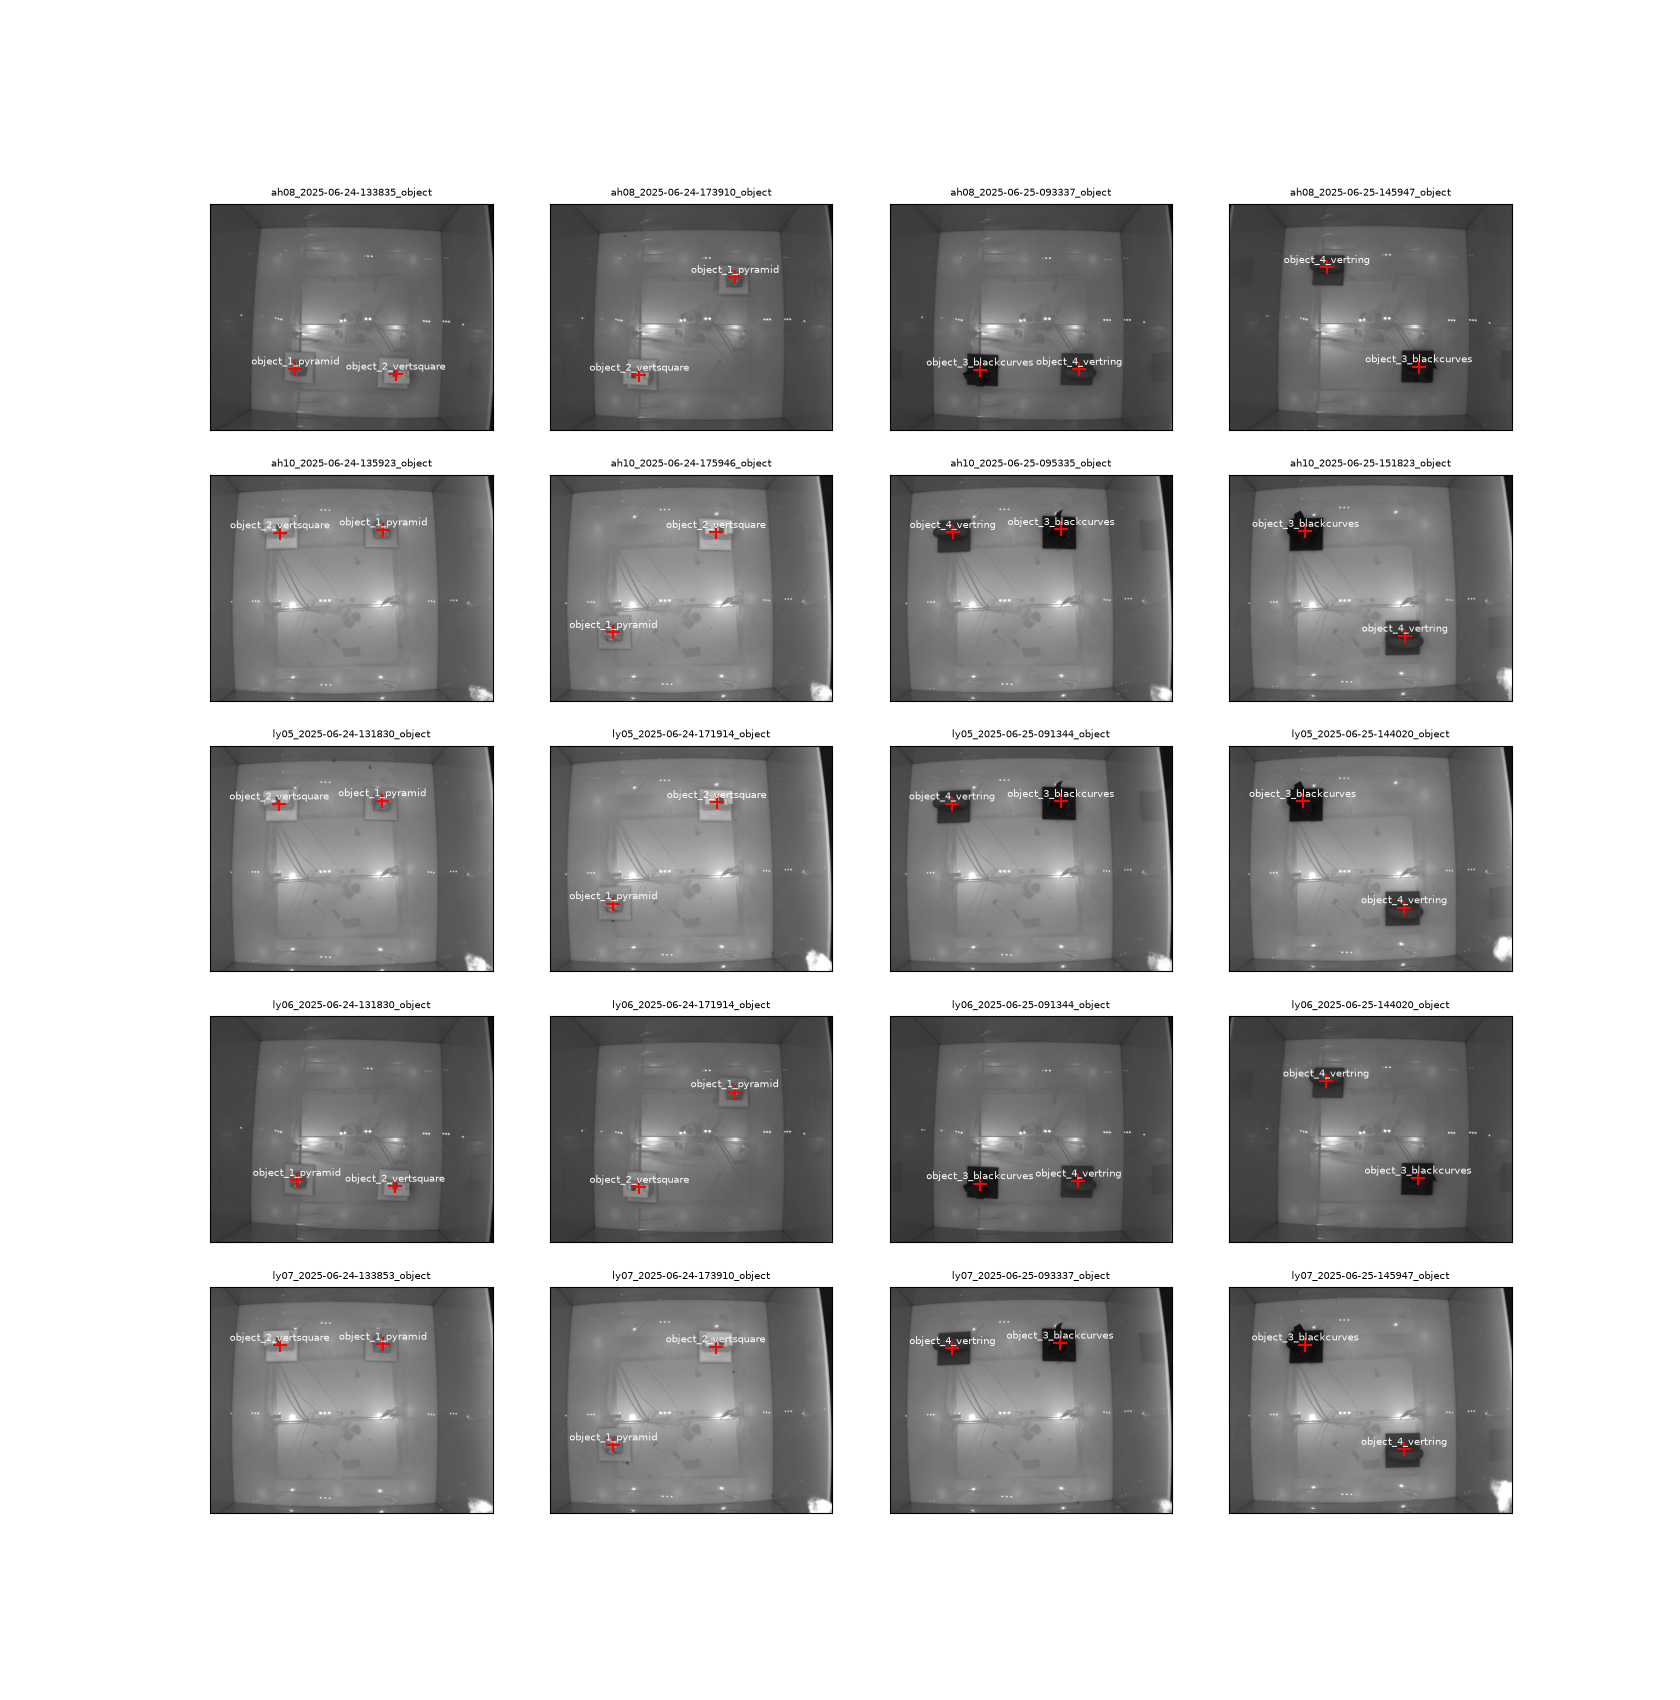

In [9]:
if OBJ_CSV.exists():
    d = pd.read_csv(OBJ_CSV)
    d = d[d.object_label != 'NONE']
    frames = d.frame.unique()
    n = len(frames); cols = 4; rows_ = int(np.ceil(n / cols))
    fig2, axes = plt.subplots(rows_, cols, figsize=(4.2 * cols, 3.4 * rows_))
    for a, f in zip(np.atleast_1d(axes).ravel(), frames):
        a.imshow(mpimg.imread(FRAMES / f)); a.set_xticks([]); a.set_yticks([]); a.set_title(f.replace('_median.png', ''), fontsize=7)
        for _, r in d[d.frame == f].iterrows():
            a.plot(r.x_px, r.y_px, 'r+', ms=10, mew=1.5); a.text(r.x_px, r.y_px - 20, r.object_label, color='w', fontsize=7, ha='center')
    for a in np.atleast_1d(axes).ravel()[n:]: a.axis('off')
    print(d.groupby(['mouse']).object_label.value_counts().to_string())
else:
    print('nothing marked yet')